# Online Appendix: EmbeddingGemma 2 Robustness Check

Writes `Appendix_Gemma.tex`, the section of the Online Appendix that compares the main analysis (fine-tuned DoubleMLDeep embeddings, `main/`) with the re-run using off-the-shelf EmbeddingGemma 2 embeddings (text + image, 256 dimensions, `gemma/`). All tables and numbers are read from the outputs of the executed notebooks:

| content | fine-tuned embeddings | EmbeddingGemma 2 |
| --- | --- | --- |
| model and inference settings | | `gemma/data/embeddings/embeddinggemma2_txtimg.json` |
| clusters, closest products | | `../outputs/01_1_create_dataset_txt_img/cluster_overview.csv`, `../outputs/02_cluster_centroid_products/collage_similarity_cluster_*.png` |
| predictive performance (test $R^2$) | `main/code/03_1_predictive_performance_txt_img.ipynb` | `03_1_predictive_performance_txt_img.ipynb` |
| homogeneous elasticities | `main/output/04_evaluation/homogeneous_elasticity_estimates.csv` | `../outputs/04_evaluation/homogeneous_elasticity_estimates.csv` |
| sensitivity analysis | `main/output/04_evaluation/sensitivity_*.csv` | `../outputs/04_evaluation/sensitivity_*.csv`, `key_results.json` |
| heterogeneous elasticities | `../outputs/04_evaluation_comparison/finetuned/{cate_estimates,chi2_tests,sorted_effects}.csv`, `main/output/04_evaluation/cluster_sorted_effects.png` | `../outputs/04_evaluation/{cate_estimates,chi2_tests,sorted_effects}.csv`, `cluster_sorted_effects.png` |

The observed-covariate benchmark of the fine-tuned embeddings is taken from the re-run `../outputs/04_evaluation_comparison/finetuned`, which is checked against `main/output/04_evaluation` below.

Requires `04_evaluation.ipynb` (default parameters and the `finetuned` run of `04_evaluation_comparison.ipynb`). Run from `gemma/code`.

In [1]:
import os
import re
import json
import shutil
from html.parser import HTMLParser
from pathlib import Path

import numpy as np
import pandas as pd
import nbformat

# Parameters
output_dir = "../outputs/05_appendix_gemma"
paper_figure_dir = "paper/figures_revision/gemma"  # figure path used in Appendix_Gemma.tex (Overleaf project)

main_dir = "../../main/output/04_evaluation"
gemma_dir = "../outputs/04_evaluation"
finetuned_rerun_dir = "../outputs/04_evaluation_comparison/finetuned"
Path(output_dir, "figures").mkdir(parents=True, exist_ok=True)

## Inputs and consistency checks

In [2]:
meta = json.load(open("../data/embeddings/embeddinggemma2_txtimg.json"))

# homogeneous elasticities (Models I-1 to I-3)
ate_main = pd.read_csv(os.path.join(main_dir, "homogeneous_elasticity_estimates.csv"), index_col=0)
ate_gemma = pd.read_csv(os.path.join(gemma_dir, "homogeneous_elasticity_estimates.csv"), index_col=0)
assert list(ate_main.index) == list(ate_gemma.index)

# sensitivity analysis
sens_main = pd.read_csv(os.path.join(main_dir, "sensitivity_calibrated.csv"))
sens_gemma_main_shares = pd.read_csv(os.path.join(gemma_dir, "sensitivity_main_shares.csv"))
sens_gemma_own = pd.read_csv(os.path.join(gemma_dir, "sensitivity_calibrated.csv"))
rv_main = pd.read_csv(os.path.join(main_dir, "sensitivity_robustness_values.csv")).set_index("null_hypothesis")
rv_gemma = pd.read_csv(os.path.join(gemma_dir, "sensitivity_robustness_values.csv")).set_index("null_hypothesis")
assert np.allclose(sens_gemma_main_shares["share"], sens_main["share"], rtol=0, atol=0)
key_gemma = json.load(open(os.path.join(gemma_dir, "key_results.json")))["sensitivity"]
key_main = json.load(open(os.path.join(finetuned_rerun_dir, "key_results.json")))["sensitivity"]

# the re-run of the fine-tuned specification reproduces main/output/04_evaluation
for file_name in ["homogeneous_elasticity_estimates.csv", "sensitivity_calibrated.csv", "sensitivity_robustness_values.csv"]:
    a = pd.read_csv(os.path.join(main_dir, file_name)).select_dtypes("number")
    b = pd.read_csv(os.path.join(finetuned_rerun_dir, file_name)).select_dtypes("number")
    assert np.allclose(a.values, b.values, rtol=0, atol=1e-9), file_name
assert np.isclose(key_main["scaled_implied_rv"], sens_main.loc[0, "share"], rtol=0, atol=1e-12)
assert np.isclose(key_gemma["scaled_implied_rv"], sens_gemma_own.loc[0, "share"], rtol=0, atol=1e-12)
print("fine-tuned re-run reproduces main/output/04_evaluation")

fine-tuned re-run reproduces main/output/04_evaluation


In [3]:
class _TableParser(HTMLParser):
    """Minimal parser for the HTML representation of a pandas DataFrame."""

    def __init__(self):
        super().__init__()
        self.rows, self._row, self._cell = [], None, None

    def handle_starttag(self, tag, attrs):
        if tag == "tr":
            self._row = []
        elif tag in ("td", "th") and self._row is not None:
            self._cell = ""

    def handle_endtag(self, tag):
        if tag in ("td", "th") and self._cell is not None:
            self._row.append(self._cell.strip())
            self._cell = None
        elif tag == "tr" and self._row is not None:
            self.rows.append(self._row)
            self._row = None

    def handle_data(self, data):
        if self._cell is not None:
            self._cell += data


def read_result_table(notebook, variable):
    """Read the DataFrame displayed by the cell `<variable> = pd.concat(...)` of an executed notebook."""
    nb = nbformat.read(notebook, as_version=4)
    cells = [c for c in nb.cells if c.cell_type == "code" and re.match(rf"{variable} = pd\.concat", c.source.strip())]
    assert len(cells) == 1, (notebook, variable)
    html = [o["data"]["text/html"] for o in cells[0].outputs if "data" in o and "text/html" in o["data"]]
    assert len(html) == 1
    parser = _TableParser()
    parser.feed(html[0])
    header, *body = parser.rows
    df = pd.DataFrame([r[1:] for r in body], index=[r[0] for r in body], columns=header[1:]).astype(float)
    return df


r2 = {}
for label, notebook in [
    ("finetuned", "../../main/code/03_1_predictive_performance_txt_img.ipynb"),
    ("gemma", "03_1_predictive_performance_txt_img.ipynb"),
]:
    levels = read_result_table(notebook, "results_df")
    diffs = read_result_table(notebook, "results_df_diff")
    r2[label] = pd.DataFrame(
        {
            "Q": levels["R2 Q Test"],
            "P": levels["R2 P Test"],
            "dQ": diffs["R2 Q Test"],
            "dP": diffs["R2 P Test"],
        }
    )
# the tabular-only benchmarks do not depend on the embeddings
for row in ["OLS (Tabular)", "Boosting (Tabular)"]:
    assert np.allclose(r2["finetuned"].loc[row], r2["gemma"].loc[row], rtol=0, atol=1e-12)
pd.concat(r2, axis=1).round(4)

finetuned                           gemma  \
                                          Q       P      dQ      dP       Q   
OLS (Tabular)                        0.2084  0.1582  0.0708  0.0064  0.2084   
Boosting (Tabular)                   0.4751  0.1854  0.1513 -0.0043  0.4751   
OLS (Tabular + PCA)                  0.4647  0.6063  0.0706  0.0064  0.3105   
Boosting (Tabular + PCA)             0.5322  0.6436  0.1379 -0.0045  0.5464   
OLS (Tabular + Similarities)         0.4727  0.5702  0.0707  0.0064  0.3030   
Boosting (Tabular + Similarities)    0.5258  0.6253  0.1463 -0.0024  0.5320   
OLS (Tabular + Embeddings)           0.5124  0.6214  0.0547 -0.0027  0.4088   
Boosting (Tabular + Embeddings)      0.5528  0.6564  0.1011 -0.0119  0.5877   
Deep Time Independent                0.5044  0.6726  0.1089  0.0115  0.5044   
Deep Time Dependent                  0.5953  0.6669  0.1217  0.0165  0.5953   

                                                           
                                        P      dQ      dP  
OLS (Tabular)                      0.1582  0.0708  0.0064  
Boosting (Tabular)                 0.1854  0.1513 -0.0043  
OLS (Tabular + PCA)                0.1650  0.0709  0.0067  
Boosting (Tabular + PCA)           0.3756  0.1707  0.0047  
OLS (Tabular + Similarities)       0.1680  0.0709  0.0066  
Boosting (Tabular + Similarities)  0.3222  0.1680  0.0054  
OLS (Tabular + Embeddings)         0.5230  0.0707  0.0055  
Boosting (Tabular + Embeddings)    0.5554  0.1836  0.0156  
Deep Time Independent              0.6726  0.1089  0.0115  
Deep Time Dependent                0.6669  0.1217  0.0165

## Tables

In [4]:
def num(x, digits=3):
    """Number in math mode (proper minus sign)."""
    return f"${x:.{digits}f}$"


def pct(x, digits=2):
    """Test R^2 in percent; negative values are set to 0 as in the main text."""
    return f"{100 * max(x, 0.0):.{digits}f}"


# --- predictive performance -----------------------------------------------------------
r2_rows = [
    ("Linear Reg [all tabular]", "OLS (Tabular)"),
    ("Boosted Trees Reg [all tabular]", "Boosting (Tabular)"),
    None,
    ("Linear Reg [+5 PCAs]", "OLS (Tabular + PCA)"),
    ("Linear Reg [+5 Similarities]", "OLS (Tabular + Similarities)"),
    ("Linear Reg [+256 Embeddings]", "OLS (Tabular + Embeddings)"),
    ("Boosted Trees Reg [+5 PCAs]", "Boosting (Tabular + PCA)"),
    ("Boosted Trees Reg [+5 Similarities]", "Boosting (Tabular + Similarities)"),
    ("Boosted Trees Reg [+256 Embeddings]", "Boosting (Tabular + Embeddings)"),
]
lines = []
for row in r2_rows:
    if row is None:
        lines.append("\\midrule")
        continue
    label, key = row
    cells = []
    for target in ["Q", "P", "dQ", "dP"]:
        a, b = r2["finetuned"].loc[key, target], r2["gemma"].loc[key, target]
        if key in ("OLS (Tabular)", "Boosting (Tabular)"):
            cells.append(f"\\multicolumn{{2}}{{c}}{{{pct(a)}}}")
        else:
            cells.append(f"{pct(a)} & {pct(b)}")
    lines.append(f"{label} & " + " & ".join(cells) + "\\\\")
table_r2 = "\n".join(lines)

# --- homogeneous elasticities -----------------------------------------------------------
lines = []
for spec in ate_main.index:
    cells = []
    for df in [ate_main, ate_gemma]:
        r = df.loc[spec]
        cells.append(f"{num(r['coef'])} & {num(r['std err'])} & [{num(r['lower'])}, {num(r['upper'])}]")
    lines.append(f"{{{spec}}} & " + " & ".join(cells) + "\\\\")
table_ate = "\n".join(lines)


# --- sensitivity at the residual shares of the main analysis ----------------------------
def sensitivity_rows(df):
    return "\n".join(
        f"{r['scenario']} & {100 * r['share']:.2f}\\% & {num(r['theta_lower'])} & {num(r['theta_upper'])} "
        f"& {num(r['ci_lower'])} & {num(r['ci_upper'])}\\\\"
        for _, r in df.iterrows()
    )


table_sens_main = sensitivity_rows(sens_main)
table_sens_gemma = sensitivity_rows(sens_gemma_main_shares)

print(table_r2, table_ate, table_sens_main, table_sens_gemma, sep="\n\n")

Linear Reg [all tabular] & \multicolumn{2}{c}{20.84} & \multicolumn{2}{c}{15.82} & \multicolumn{2}{c}{7.08} & \multicolumn{2}{c}{0.64}\\
Boosted Trees Reg [all tabular] & \multicolumn{2}{c}{47.51} & \multicolumn{2}{c}{18.54} & \multicolumn{2}{c}{15.13} & \multicolumn{2}{c}{0.00}\\
\midrule
Linear Reg [+5 PCAs] & 46.47 & 31.05 & 60.63 & 16.50 & 7.06 & 7.09 & 0.64 & 0.67\\
Linear Reg [+5 Similarities] & 47.27 & 30.30 & 57.02 & 16.80 & 7.07 & 7.09 & 0.64 & 0.66\\
Linear Reg [+256 Embeddings] & 51.24 & 40.88 & 62.14 & 52.30 & 5.47 & 7.07 & 0.00 & 0.55\\
Boosted Trees Reg [+5 PCAs] & 53.22 & 54.64 & 64.36 & 37.56 & 13.79 & 17.07 & 0.00 & 0.47\\
Boosted Trees Reg [+5 Similarities] & 52.58 & 53.20 & 62.53 & 32.23 & 14.63 & 16.80 & 0.00 & 0.54\\
Boosted Trees Reg [+256 Embeddings] & 55.28 & 58.77 & 65.64 & 55.54 & 10.11 & 18.36 & 0.00 & 1.56\\

{I-1. Linear ($P_{t-1}$, $Q_{t-1}$)} & $-0.690$ & $0.040$ & [$-0.756$, $-0.624$] & $-0.690$ & $0.040$ & [$-0.756$, $-0.624$]\\
{I-1. Linear ($P_{t-1}$,

## Appendix_Gemma.tex

Text of the section (`templates/Appendix_Gemma.tex` with placeholders `<<name>>`). Qualitative statements of the text are checked against the estimates.

ARI = 0.0596, NMI(cluster, subcategory) = {'finetuned': 0.062357562617389804, 'gemma': 0.2944722017356626}
cluster    0    1    2    3    4
cluster                         
0        351  290  102  257  280
1        622  388  104  467  345
2        332  198  479  269  578
3        457  479   76  473  219
4          1  696    8   72    6
          embedding  cluster  # Products                                      Top product types
gemma_txtimg_dim256        0        1763 Trucks (31%) / Residual (22%) / Cars & Race Cars (17%)
gemma_txtimg_dim256        1        2051 Cars & Race Cars (48%) / Trucks (19%) / Residual (17%)
gemma_txtimg_dim256        2         769   Skateboards (87%) / Residual (9%) / Race Tracks (1%)
gemma_txtimg_dim256        3        1538       Train Sets (30%) / Trucks (20%) / Residual (16%)
gemma_txtimg_dim256        4        1428  Cars & Race Cars (73%) / Residual (13%) / Trucks (8%)


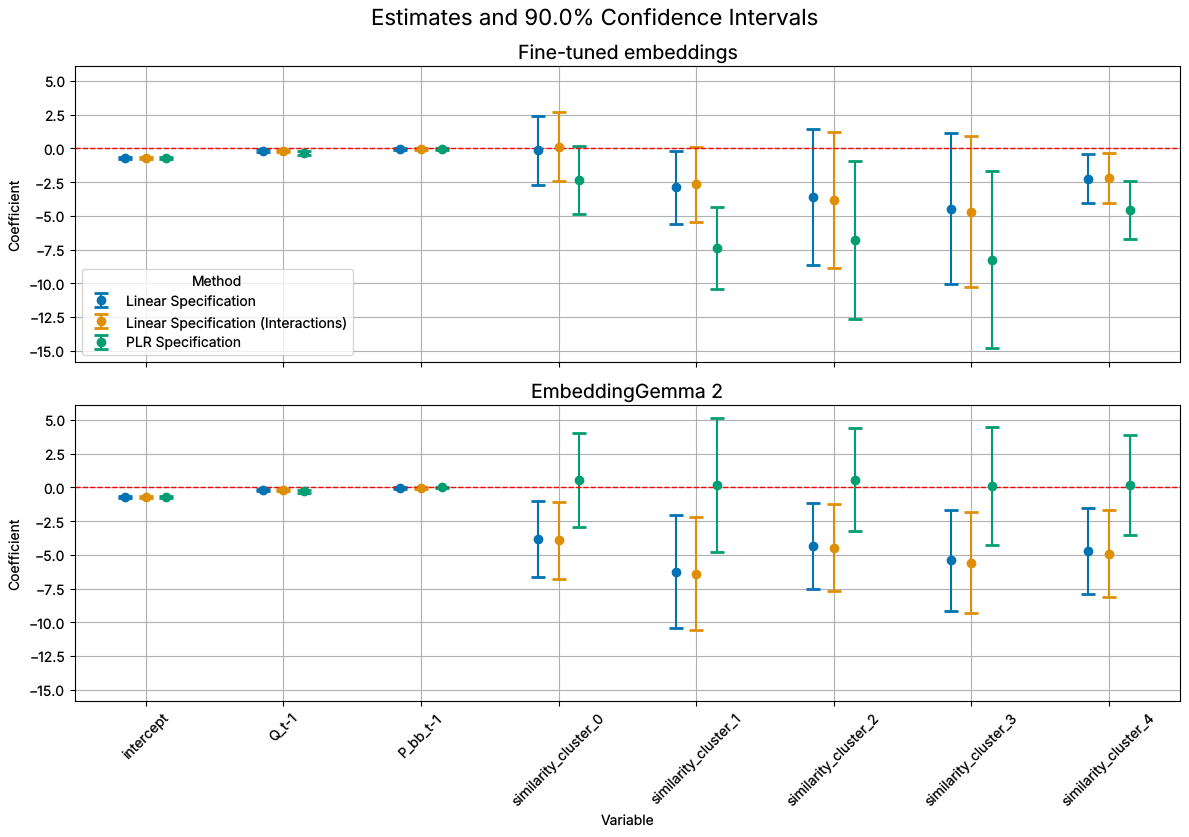

PLR sorted effects quantiles (5/50/95%): [-1.331 -0.723 -0.202] [-1.28  -0.654 -0.251] corr: 0.773 share > -0.5: 0.25851055440182963 0.2753607949317841


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score


def f3(x):
    return f"{x:.3f}"


def m3(x):
    """Number with three decimals in math mode."""
    return f"${x:.3f}$"


def m2(x):
    """Number with two decimals in math mode."""
    return f"${x:.2f}$"


def p2(x):
    """Share in percent with two decimals."""
    return f"{100 * x:.2f}\\%"


def pval(p):
    return "${<}\\,0.001$" if p < 0.001 else f"{p:.3f}"


# --- clusters -----------------------------------------------------------------------------
sim_cols = [f"similarity_cluster_{k}" for k in range(5)]
assignments = {}
for label, data_dir in [("finetuned", "../../main/data"), ("gemma", "../data")]:
    frames = [
        pd.read_csv(f"{data_dir}/dataset_txt_only_False_embeddings_True_{split}.zip", usecols=["ASIN", "date"] + sim_cols)
        for split in ["train", "val"]
    ]
    df = pd.concat(frames, ignore_index=True)
    df["cluster"] = df[sim_cols].values.argmax(axis=1)
    assignments[label] = df
assert assignments["finetuned"][["ASIN", "date"]].equals(assignments["gemma"][["ASIN", "date"]])
# product level: first panel row of each product, as in 01_1_create_dataset_txt_img.ipynb
subcat = pd.concat(
    [pd.read_csv(f"../../main/data/dataset_txt_only_False_embeddings_True_{split}.zip", usecols=["subcat_aggregated"]) for split in ["train", "val"]],
    ignore_index=True,
)["subcat_aggregated"]
products = {
    label: df.assign(subcat=subcat.values).groupby("ASIN").first() for label, df in assignments.items()
}
assert products["finetuned"].index.equals(products["gemma"].index)
ari = adjusted_rand_score(products["finetuned"]["cluster"], products["gemma"]["cluster"])
nmi = {label: normalized_mutual_info_score(p["subcat"], p["cluster"]) for label, p in products.items()}
print(f"ARI = {ari:.4f}, NMI(cluster, subcategory) = {nmi}")
print(pd.crosstab(products["finetuned"]["cluster"], products["gemma"]["cluster"]))

overview = pd.read_csv("../outputs/01_1_create_dataset_txt_img/cluster_overview.csv")
print(overview[overview["embedding"] == "gemma_txtimg_dim256"].to_string(index=False))

assert ari < 0.1
assert nmi["gemma"] > 3 * nmi["finetuned"]

cluster_text = (
    "\\revised{Figure~\\ref{fig:gemma_clusters} shows the four products closest to each of the five cluster centers: "
    "toddler construction-truck sets, 1:64 scale die-cast cars, fingerboards, toy train sets, and larger-scale die-cast "
    f"model cars. Over all {len(products['gemma']):,} products, these clusters are more closely aligned with the "
    f"{subcat.nunique()} product subcategories than the fine-tuned clusters (normalized mutual information "
    f"{nmi['gemma']:.2f} vs.\\ {nmi['finetuned']:.2f}), and the two cluster assignments differ substantially "
    f"(adjusted Rand index {ari:.2f}).}}"
)

cluster_figure_rows = "\n".join(
    f"Cluster {k} & \\includegraphics[width=.5\\textwidth]{{{paper_figure_dir}/collage_similarity_cluster_{k}.png}}\\\\[0.1cm]"
    for k in range(5)
)

# --- predictive performance -------------------------------------------------------------------
ft, eg = r2["finetuned"], r2["gemma"]
q_emb_ft, q_emb_eg = ft.loc["Boosting (Tabular + Embeddings)", "Q"], eg.loc["Boosting (Tabular + Embeddings)", "Q"]
p_emb_ft, p_emb_eg = ft.loc["Boosting (Tabular + Embeddings)", "P"], eg.loc["Boosting (Tabular + Embeddings)", "P"]
p_tab = ft.loc["Boosting (Tabular)", "P"]
compressed = ["Boosting (Tabular + PCA)", "Boosting (Tabular + Similarities)"]

assert q_emb_eg > q_emb_ft and p_emb_eg < p_emb_ft
assert (ft.loc[compressed, "P"] > 0.6).all() and (eg.loc[compressed, "P"] < 0.4).all()

r2_text = (
    "\\revised{Table~\\ref{tab:gemma_r2} compares the test $R^2$ of the prediction benchmarks. With all 256 "
    "coordinates, boosted trees predict quantity levels better with EmbeddingGemma~2 than with the fine-tuned "
    f"embeddings ({p2(q_emb_eg)} vs.\\ {p2(q_emb_ft)}) and price levels worse ({p2(p_emb_eg)} vs.\\ {p2(p_emb_ft)}). "
    "Unlike those of the fine-tuned embeddings, five principal components or cluster similarities of "
    f"EmbeddingGemma~2 retain little of the price information ({p2(eg.loc[compressed[0], 'P'])} and "
    f"{p2(eg.loc[compressed[1], 'P'])} vs.\\ {p2(ft.loc[compressed[0], 'P'])} and {p2(ft.loc[compressed[1], 'P'])}, "
    f"compared with {p2(p_tab)} without embeddings).}}"
)

# --- homogeneous elasticities -----------------------------------------------------------------
specs_emb = [s for s in ate_main.index if "X^{e}" in s or "X^{sim}" in s]
diff = (ate_gemma.loc[specs_emb, "coef"] - ate_main.loc[specs_emb, "coef"]).abs()
diff_in_se = diff / ate_main.loc[specs_emb, "std err"]
spec_e = "I-3. Boosted Trees ($P_{t-1}$, $Q_{t-1}$, $X^{e}, X^{o}_t$)"
assert spec_e in specs_emb

assert diff_in_se.max() < 0.5
assert (ate_gemma["upper"] < -0.6).all() and (ate_main["upper"] < -0.6).all()
assert np.isclose(ate_gemma.iloc[0]["coef"], ate_main.iloc[0]["coef"], rtol=0, atol=1e-12)

ate_text = (
    "\\revised{Table~\\ref{tab:gemma_ate} compares the estimates of Models I-1 to I-3. In the specifications with "
    f"embedding features, the estimates differ by at most {f3(diff.max())}, less than half a standard error. For "
    f"Model I-3 with embeddings, the estimate is {m3(ate_gemma.loc[spec_e, 'coef'])} "
    f"({f3(ate_gemma.loc[spec_e, 'std err'])}) with EmbeddingGemma~2 and {m3(ate_main.loc[spec_e, 'coef'])} "
    f"({f3(ate_main.loc[spec_e, 'std err'])}) with the fine-tuned embeddings. All upper endpoints of the 90\\% "
    "intervals lie below $-0.6$.}"
)

# --- heterogeneous elasticities ---------------------------------------------------------------
cate = {
    "Fine-tuned embeddings": pd.read_csv(os.path.join(finetuned_rerun_dir, "cate_estimates.csv")),
    "EmbeddingGemma 2": pd.read_csv(os.path.join(gemma_dir, "cate_estimates.csv")),
}
chi2 = {
    "main": pd.read_csv(os.path.join(finetuned_rerun_dir, "chi2_tests.csv")).set_index("model"),
    "gemma": pd.read_csv(os.path.join(gemma_dir, "chi2_tests.csv")).set_index("model"),
}
plr = {label: df[df["model"] == "PLR Specification"].set_index("variable") for label, df in cate.items()}
plr_ft, plr_eg = plr["Fine-tuned embeddings"], plr["EmbeddingGemma 2"]
# the fine-tuned estimates are those of the main text (table of Model II-3)
assert plr_ft["coef"].round(3).tolist() == [-0.736, -0.325, -0.049, -2.312, -7.365, -6.785, -8.255, -4.559]
assert (cate["Fine-tuned embeddings"][["model", "variable"]].values == cate["EmbeddingGemma 2"][["model", "variable"]].values).all()

palette = sns.color_palette("colorblind")
fig, axs = plt.subplots(2, 1, figsize=(12, 8.5), sharex=True, sharey=True)
for ax, (title, df) in zip(axs, cate.items()):
    models = df["model"].unique()
    variables = df["variable"].unique()
    x_positions = np.arange(len(variables))
    bar_width = 0.15
    for i, model in enumerate(models):
        df_model = df[df["model"] == model]
        ax.errorbar(
            x_positions + i * bar_width,
            df_model["coef"],
            yerr=[df_model["coef"] - df_model["lower"], df_model["upper"] - df_model["coef"]],
            fmt="o",
            label=model,
            capsize=5,
            capthick=2,
            ecolor=palette[i % len(palette)],
            color=palette[i % len(palette)],
            zorder=2,
        )
    ax.axhline(0, color="red", linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=14)
    ax.set_ylabel("Coefficient")
    ax.grid(True)
axs[0].legend(title="Method")
axs[1].set_xticks(x_positions + (len(models) - 1) * bar_width / 2, variables, rotation=45)
axs[1].set_xlabel("Variable")
fig.suptitle("Estimates and 90.0% Confidence Intervals", fontsize=16)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "figures", "cate_estimates_comparison.png"), dpi=150)
plt.show()

shutil.copy("../../main/output/04_evaluation/cluster_sorted_effects.png", os.path.join(output_dir, "figures", "sorted_effects_finetuned.png"))
shutil.copy(os.path.join(gemma_dir, "cluster_sorted_effects.png"), os.path.join(output_dir, "figures", "sorted_effects_gemma.png"))

sorted_effects = {
    "main": pd.read_csv(os.path.join(finetuned_rerun_dir, "sorted_effects.csv")),
    "gemma": pd.read_csv(os.path.join(gemma_dir, "sorted_effects.csv")),
}
assert sorted_effects["main"][["ASIN", "date"]].equals(sorted_effects["gemma"][["ASIN", "date"]])
se_ft, se_eg = sorted_effects["main"]["SortEff_deep_dml"], sorted_effects["gemma"]["SortEff_deep_dml"]
q_ft, q_eg = se_ft.quantile([0.05, 0.5, 0.95]).values, se_eg.quantile([0.05, 0.5, 0.95]).values
corr = np.corrcoef(se_ft, se_eg)[0, 1]
above_ft, above_eg = (se_ft > -0.5).mean(), (se_eg > -0.5).mean()
print("PLR sorted effects quantiles (5/50/95%):", q_ft.round(3), q_eg.round(3), "corr:", round(corr, 3), "share > -0.5:", above_ft, above_eg)

ci_excl_zero = lambda d: (d["upper"] < 0) | (d["lower"] > 0)
sim_rows = [f"similarity_cluster_{k}" for k in range(5)]
lin_eg = cate["EmbeddingGemma 2"].set_index(["model", "variable"])
p_cl = {k: chi2[k]["p_value_clusters"] for k in chi2}
assert ci_excl_zero(plr_eg.loc[["Q_t-1"]]).all() and ci_excl_zero(plr_ft.loc[["Q_t-1"]]).all()
assert not ci_excl_zero(plr_eg.loc[["P_bb_t-1"]]).any() and not ci_excl_zero(plr_ft.loc[["P_bb_t-1"]]).any()
for model in ["Linear Specification", "Linear Specification (Interactions)"]:
    assert ci_excl_zero(lin_eg.loc[model].loc[sim_rows]).all(), model
assert not ci_excl_zero(plr_eg.loc[sim_rows]).any()
assert (p_cl["gemma"] < 0.05).all()
assert 0.7 < corr < 0.9 and (se_ft > -0.5).any() and (se_eg > -0.5).any() and (se_ft < -0.5).any() and (se_eg < -0.5).any()

models_ii = ["Linear Specification", "Linear Specification (Interactions)", "PLR Specification"]
het_text = (
    "\\revised{Figure~\\ref{fig:gemma_cate} compares the parameters of the elasticity function (Models II-1 to II-3). "
    f"The average effect of Model II-3 is {m3(plr_eg.loc['intercept', 'coef'])} "
    f"$[{plr_eg.loc['intercept', 'lower']:.3f}, {plr_eg.loc['intercept', 'upper']:.3f}]$ with EmbeddingGemma~2, "
    f"compared with {m3(plr_ft.loc['intercept', 'coef'])} "
    f"$[{plr_ft.loc['intercept', 'lower']:.3f}, {plr_ft.loc['intercept', 'upper']:.3f}]$. The modifier of the lagged "
    f"quantity is similar ({m3(plr_eg.loc['Q_t-1', 'coef'])} vs.\\ {m3(plr_ft.loc['Q_t-1', 'coef'])}), and that of the "
    "lagged price is insignificant with both embeddings. The cluster similarities refer to different clusters and are "
    "not comparable one-to-one. With EmbeddingGemma~2, their 90\\% intervals exclude zero in Models II-1 and II-2 but "
    "not in Model II-3; jointly, they are significant in all three models ($\\chi^2$ $p$-values "
    + ", ".join(pval(p_cl["gemma"][m]) for m in models_ii[:2]) + f", and {pval(p_cl['gemma'][models_ii[2]])}, compared with "
    + ", ".join(pval(p_cl["main"][m]) for m in models_ii[:2]) + f", and {pval(p_cl['main'][models_ii[2]])}).}}\n\n"
    "\\revised{Figure~\\ref{fig:gemma_sorted} shows the sorted effects. For Model II-3, the 5\\%, 50\\%, and 95\\% "
    f"quantiles of the fitted elasticities are {m2(q_eg[0])}, {m2(q_eg[1])}, and {m2(q_eg[2])} with EmbeddingGemma~2, "
    f"compared with {m2(q_ft[0])}, {m2(q_ft[1])}, and {m2(q_ft[2])}, and the fitted effects of the two embeddings are "
    f"strongly correlated across observations ({corr:.2f}). With both embeddings, fitted responses span both sides of "
    f"$-0.5$ ({100 * above_eg:.1f}\\% and {100 * above_ft:.1f}\\% of the observations lie above $-0.5$).}}"
)

# --- sensitivity ------------------------------------------------------------------------------
ci_eg, ci_ft = sens_gemma_main_shares["ci_upper"], sens_main["ci_upper"]
own_ci = sens_gemma_own["ci_upper"]
assert (ci_eg < 0).all() and (ci_ft < 0).all()
assert (ci_eg.iloc[:2] < -0.5).all() and (ci_ft.iloc[:2] < -0.5).all()
assert ci_eg.iloc[2] < -0.5 < ci_ft.iloc[2] and ci_ft.iloc[2] - ci_eg.iloc[2] < 0.01
assert key_gemma["implied_rho"] < key_main["implied_rho"]
assert key_gemma["scaled_implied_rv"] < key_main["scaled_implied_rv"]
assert (own_ci < -0.5).all()

sensitivity_text = (
    "\\revised{Table~\\ref{tab:gemma_sensitivity} evaluates Model I-3 with embeddings at the residual shares of "
    "Table~\\ref{tab:sensitivity_calibrated}. The upper confidence bounds are "
    f"{m3(ci_eg[0])}, {m3(ci_eg[1])}, and {m3(ci_eg[2])} with EmbeddingGemma~2, compared with {m3(ci_ft[0])}, "
    f"{m3(ci_ft[1])}, and {m3(ci_ft[2])}. A negative effect is robust in all three scenarios, and elastic "
    "demand is robust at the calibration and its 1.5 multiple for both embeddings. At twice the calibration, the upper "
    "confidence bound lies marginally below $-0.5$ with EmbeddingGemma~2 and marginally above it with the fine-tuned "
    f"embeddings (it reaches $-0.5$ at {p2(rv_gemma.loc[-0.5, 'RVa'])} and {p2(rv_main.loc[-0.5, 'RVa'])}). The "
    "observed-covariate benchmark of EmbeddingGemma~2 has a weaker alignment "
    f"($|\\tilde\\rho|={key_gemma['implied_rho']:.3f}$ vs.\\ ${key_main['implied_rho']:.3f}$) and implies a smaller "
    f"calibration, $r_0={100 * key_gemma['scaled_implied_rv']:.2f}\\%$; at 1, 1.5, and 2 times this calibration, the "
    f"upper confidence bounds are {m3(own_ci[0])}, {m3(own_ci[1])}, and {m3(own_ci[2])}.}}"
)

conclusion_text = (
    "\\revised{Overall, the homogeneous elasticities, the average effect and the lagged-quantity modifier of the "
    "heterogeneous model, the distribution of the sorted effects, and the robustness to omitted confounding are similar "
    "without fine-tuning. The two embeddings differ mainly in their compressed features: the principal components and "
    "cluster similarities of the fine-tuned embeddings retain the price information and cut across product categories, "
    "whereas those of EmbeddingGemma~2 follow product categories and carry little price information.}"
)

FILL = {
    "revision": meta["model_revision"][:7],
    "figure_dir": paper_figure_dir,
    "cluster_text": cluster_text,
    "cluster_figure_rows": cluster_figure_rows,
    "r2_text": r2_text,
    "table_r2": table_r2,
    "ate_text": ate_text,
    "table_ate": table_ate,
    "het_text": het_text,
    "sensitivity_text": sensitivity_text,
    "alpha_main": f3(sens_main.loc[0, "theta"]),
    "alpha_gemma": f3(sens_gemma_main_shares.loc[0, "theta"]),
    "table_sens_main": table_sens_main,
    "table_sens_gemma": table_sens_gemma,
    "r0_main_7": f"{key_main['scaled_implied_rv']:.7f}",
    "conclusion_text": conclusion_text,
}
assert np.isclose(sens_main.loc[0, "theta"], ate_main.loc[spec_e, "coef"], rtol=0, atol=1e-12)
assert np.isclose(sens_gemma_main_shares.loc[0, "theta"], ate_gemma.loc[spec_e, "coef"], rtol=0, atol=1e-12)


In [6]:
with open("templates/Appendix_Gemma.tex") as f:
    template = f.read()
template = template.split("\n", 2)[2]  # drop the template comment lines

text = template
for key, value in FILL.items():
    placeholder = "<<" + key + ">>"
    assert text.count(placeholder) >= 1, key
    text = text.replace(placeholder, value)
assert not re.findall(r"<<\w+>>", text), re.findall(r"<<\w+>>", text)

with open(os.path.join(output_dir, "Appendix_Gemma.tex"), "w") as f:
    f.write(text)
for k in range(5):
    shutil.copy(
        f"../outputs/02_cluster_centroid_products/collage_similarity_cluster_{k}.png",
        os.path.join(output_dir, "figures", f"collage_similarity_cluster_{k}.png"),
    )
print(text)

\hyphenation{EmbeddingGemma}
\begingroup
\setlength{\emergencystretch}{3em}% the model name is not hyphenated
\section{Robustness Check: Embeddings without Fine-Tuning}\label{app:gemma}

\revised{This section repeats the analysis with off-the-shelf embeddings that are not fine-tuned. The workflow is exactly the same as in the main analysis (Section~\ref{app:workflow}), except that the fine-tuning in step~2 is omitted and the embeddings in step~3 are computed with EmbeddingGemma~2 \citep{embeddinggemma2}. All features are computed with Algorithm~\ref{alg:features}; the sample split, the estimation sample, the tabular controls, the learners, and the random seeds are unchanged.}

\revised{EmbeddingGemma~2 is an open multimodal embedding model released by Google DeepMind in October 2026. Built on Gemma 4, it maps text, images, video, and audio into a shared 768-dimensional space. Of its 740M parameters, we use the 270M-parameter text model and the 170M-parameter vision encoder. The descrip